# 🧠 Deep Learning PR 6

## Opening the Transformer: Attention, Encoder, Decoder & Inference

**Practical Report 6 — Red & White Skill Education**

**Objective:** Understand Transformer components by inspecting pretrained models, implementing attention equations, and evaluating model behaviour without training or fine-tuning.

**Models:** DistilBERT, GPT-2 and T5-small  
**Dataset:** 200 IMDb test reviews + 3 student-selected text passages  
**Approach:** Pretrained inference only — no model training.

---

## 📌 Project Overview

Transformers process relationships between tokens using attention. In this practical, we will inspect the mathematics behind attention, compare encoder-only, decoder-only and encoder-decoder architectures, and test limitations such as truncation, latency and hallucination.

### Project objectives
- Understand tokenisation, model pipelines and the history of Transformers.
- Implement scaled dot-product attention and Luong attention using NumPy.
- Inspect real attention heads, positional information and Layer Normalization.
- Compare bidirectional attention, causal masking and cross-attention.
- Evaluate a pretrained sentiment model and build a small text toolkit.

### Notebook roadmap
1. Introduction, history, pipelines and tokenizer
2. Self-attention and scaled dot-product attention
3. Multi-head attention, positional encoding and Layer Normalization
4. Encoder architecture and masked self-attention
5. Cross-attention, decoder architecture and inference
6. Evaluation, mini application and practical disadvantages

In [1]:
import os
import re
import time
import random
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from datasets import load_dataset
from transformers import pipeline, AutoTokenizer, AutoModel, AutoModelForSequenceClassification, AutoModelForMaskedLM, AutoModelForCausalLM, T5ForConditionalGeneration, T5Tokenizer

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
PLOTS_DIR = Path("plots")
PLOTS_DIR.mkdir(exist_ok=True)

SENTIMENT_MODEL_ID = "distilbert-base-uncased-finetuned-sst-2-english"
GPT2_MODEL_ID = "gpt2"
T5_MODEL_ID = "t5-small"

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)
print("Plots folder:", PLOTS_DIR.resolve())

PyTorch version: 2.14.1+cpu
Device: cpu
Plots folder: D:\RnW\Deep Learning\Transformer_Attention_Explorer\plots


**Environment note:** The models are pretrained and are used in evaluation/inference mode. The first run downloads public model weights and the IMDb sample, so an internet connection is required once. All experiments are designed to run on a normal CPU; timing will depend on the computer.

# Task 1: Introduction, History, Pipelines & Tokenizer

### Objective
Run a sentiment pipeline, inspect tokenisation and model configuration, and summarise why Transformers became important.

**Expected output:** Pipeline predictions, history table, token IDs and masks, model configuration and parameter count.

### 1.1 First look at the sentiment pipeline

A pipeline combines three steps: tokenisation, the model's forward pass, and post-processing that converts logits into readable labels and scores.

In [2]:
sentiment_pipe = pipeline("sentiment-analysis", model=SENTIMENT_MODEL_ID, device=0 if DEVICE == "cuda" else -1)

sample_sentences = ["The movie was brilliant and the performances were outstanding.",
                    "I disliked almost every minute of this film.",
                    "The story was okay, but the ending was disappointing.",
                    "I thought I would hate it, but it surprised me in a good way.",
                    "The film was not bad, although it was not especially memorable."]

pipeline_results = sentiment_pipe(sample_sentences)

pipeline_demo = pd.DataFrame({"text": sample_sentences,
                              "label": [r["label"] for r in pipeline_results],
                              "score": [round(r["score"], 4) for r in pipeline_results]})
display(pipeline_demo)

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

,text,label,score
0,The movie was brilliant and the performances w...,POSITIVE,0.9999
1,I disliked almost every minute of this film.,NEGATIVE,0.9994
2,"The story was okay, but the ending was disappo...",NEGATIVE,0.9990
3,"I thought I would hate it, but it surprised me...",POSITIVE,0.9998
4,"The film was not bad, although it was not espe...",POSITIVE,0.9641


**Interpretation**

- The label is the model's predicted sentiment class, while the score is its confidence for that predicted class.
- Negation and mixed opinions can be difficult because a short sentence may contain both positive and negative cues.
- A high score does not guarantee that the prediction is correct.

### 1.2 Transformer history

The timeline below highlights the main steps from attention-based sequence models to modern Transformer applications.

In [3]:
history = pd.DataFrame([[2014, "Sequence-to-sequence models", "Encoder-decoder learning for mapping one sequence to another."],
                        [2015, "Bahdanau / Luong attention", "The decoder can focus on relevant encoder states instead of one fixed context vector."],
                        [2017, "Attention Is All You Need", "The Transformer uses attention instead of recurrent processing."],
                        [2018, "BERT and GPT", "Pretraining became a strong starting point for language understanding and generation."],
                        [2019, "GPT-2, T5 and DistilBERT", "Generation, text-to-text learning and model distillation advanced."],
                        ["2020+", "Large language models and Vision Transformers", "Transformer architectures expanded across language, images, code and other domains."]],
                       columns=["Year", "Model / paper", "Why it mattered"])
display(history)

,Year,Model / paper,Why it mattered
0,2014,Sequence-to-sequence models,Encoder-decoder learning for mapping one seque...
1,2015,Bahdanau / Luong attention,The decoder can focus on relevant encoder stat...
2,2017,Attention Is All You Need,The Transformer uses attention instead of recu...
3,2018,BERT and GPT,Pretraining became a strong starting point for...
4,2019,"GPT-2, T5 and DistilBERT","Generation, text-to-text learning and model di..."
5,2020+,Large language models and Vision Transformers,Transformer architectures expanded across lang...


**What problem did Transformers address?**

RNNs and LSTMs process tokens sequentially, which limits parallel computation and can make long-range dependencies difficult to preserve. Self-attention lets each token directly compare itself with other tokens in the same sequence. This supports parallel processing during training and provides flexible access to context, although attention has a substantial cost for long sequences.

### 1.3 Impact and disadvantages

**Impact**

- Machine translation and summarisation
- Search, question answering and semantic retrieval
- Chat assistants and text generation
- Code completion and programming assistance
- Image understanding and generation
- Scientific applications such as protein-structure modelling

**Disadvantages**
- Standard self-attention has quadratic cost with sequence length.
- Models have a fixed context window.
- Large models require substantial memory and compute.
- Pretraining requires large datasets and resources.
- Generative models may hallucinate plausible but incorrect information.
- Internal attention patterns do not provide a complete explanation of model behaviour.

### 1.4 Tokenizer in action

Tokenizers convert text into model-specific subword tokens and integer IDs. Special tokens help mark sequence boundaries or classification inputs.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(SENTIMENT_MODEL_ID)

text = "Transformers are surprisingly easy to understand."
tokens = tokenizer.tokenize(text)
encoded = tokenizer(text)

print("Text:", text)
print("Tokens:", tokens)
print("Input IDs:", encoded["input_ids"])
print("Attention mask:", encoded["attention_mask"])
print("Decoded IDs:", tokenizer.convert_ids_to_tokens(encoded["input_ids"]))

rare_word = "electroencephalographically"
print("\nSubword split example:")
print(rare_word, "->", tokenizer.tokenize(rare_word))

Text: Transformers are surprisingly easy to understand.
Tokens: ['transformers', 'are', 'surprisingly', 'easy', 'to', 'understand', '.']
Input IDs: [101, 19081, 2024, 10889, 3733, 2000, 3305, 1012, 102]
Attention mask: [1, 1, 1, 1, 1, 1, 1, 1, 1]
Decoded IDs: ['[CLS]', 'transformers', 'are', 'surprisingly', 'easy', 'to', 'understand', '.', '[SEP]']

Subword split example:
electroencephalographically -> ['electro', '##ence', '##pha', '##log', '##raphic', '##ally']


**Interpretation**

- Subword tokenisation can represent uncommon words by combining smaller pieces instead of requiring every complete word to exist in the vocabulary.
- The attention mask uses `1` for real tokens and `0` for padding.
- BERT-style tokenizers use `[CLS]` as a classification/sequence-start token and `[SEP]` as a separator/end marker. DistilBERT's tokenizer follows this convention.

### 1.5 Batching and padding

Padding makes sentences in a batch the same length. The attention mask identifies the real tokens so padding does not contribute as ordinary content.

In [5]:
batch_texts = ["Attention connects related words.",
               "Transformers process token relationships."]
batch_encoded = tokenizer(batch_texts, padding=True, truncation=True, return_tensors="pt")

print("Input IDs:")
print(batch_encoded["input_ids"])
print("\nAttention mask:")
print(batch_encoded["attention_mask"])
display(pd.DataFrame({"sentence": batch_texts,
                      "token_count_without_padding": [len(tokenizer(t)["input_ids"]) for t in batch_texts],
                      "padded_length": [batch_encoded["input_ids"].shape[1]] * len(batch_texts)}))

Input IDs:
tensor([[  101,  3086,  8539,  3141,  2616,  1012,   102],
        [  101, 19081,  2832, 19204,  6550,  1012,   102]])

Attention mask:
tensor([[1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1]])


,sentence,token_count_without_padding,padded_length
0,Attention connects related words.,7,7
1,Transformers process token relationships.,7,7


### 1.6 Model anatomy at a glance

Load DistilBERT's base model with eager attention so attention weights can be returned later.

In [6]:
encoder_model = AutoModel.from_pretrained(SENTIMENT_MODEL_ID, attn_implementation="eager").to(DEVICE)
encoder_model.eval()

config = encoder_model.config
config_summary = pd.DataFrame({"Property": ["Model type", "Hidden size", "Transformer layers", "Attention heads", "Vocabulary size", "Maximum position embeddings"],
                               "Value": [config.model_type, config.dim, config.n_layers, config.n_heads, config.vocab_size, config.max_position_embeddings]})
display(config_summary)

total_parameters = sum(p.numel() for p in encoder_model.parameters())
trainable_parameters = sum(p.numel() for p in encoder_model.parameters() if p.requires_grad)
print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,} (not trained in this practical)")

parameter_names = pd.DataFrame([(name, tuple(param.shape), param.numel()) for name, param in list(encoder_model.named_parameters())[:15]],
                               columns=["Parameter name", "Shape", "Parameter count"])
display(parameter_names)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased-finetuned-sst-2-english
Key                   | Status     |  | 
----------------------+------------+--+-
classifier.weight     | UNEXPECTED |  | 
pre_classifier.bias   | UNEXPECTED |  | 
classifier.bias       | UNEXPECTED |  | 
pre_classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,Property,Value
0,Model type,distilbert
1,Hidden size,768
2,Transformer layers,6
3,Attention heads,12
4,Vocabulary size,30522
5,Maximum position embeddings,512


Total parameters: 66,362,880
Trainable parameters: 66,362,880 (not trained in this practical)


,Parameter name,Shape,Parameter count
0,embeddings.word_embeddings.weight,"(30522, 768)",23440896
1,embeddings.position_embeddings.weight,"(512, 768)",393216
2,embeddings.LayerNorm.weight,"(768,)",768
3,embeddings.LayerNorm.bias,"(768,)",768
4,transformer.layer.0.attention.q_lin.weight,"(768, 768)",589824
5,transformer.layer.0.attention.q_lin.bias,"(768,)",768
6,transformer.layer.0.attention.k_lin.weight,"(768, 768)",589824
7,transformer.layer.0.attention.k_lin.bias,"(768,)",768
8,transformer.layer.0.attention.v_lin.weight,"(768, 768)",589824
9,transformer.layer.0.attention.v_lin.bias,"(768,)",768


---

# Task 2: Self-Attention & Scaled Dot-Product Attention

### Objective
Implement scaled dot-product attention and Luong dot attention in NumPy, then compare the scratch implementation with a real DistilBERT attention head.

**Expected output:** Attention heatmaps, scaling experiment, order-blindness demonstration and a numerical match with DistilBERT.

### 2.1 What is self-attention?

For each token, the model creates a Query (Q), Key (K) and Value (V). Query-Key similarity determines how strongly a token attends to other tokens. The weights are applied to the Values to form a context-aware representation.

### 2.2 Implement scaled dot-product attention

The score matrix is `Q @ K.T / sqrt(d_k)`. Softmax converts each row into weights that sum to one, and the weighted sum of V gives the output.

Q shape: (4, 8)
K shape: (4, 8)
V shape: (4, 8)
Score shape: (4, 4)
Attention output shape: (4, 8)
Row sums: [1. 1. 1. 1.]


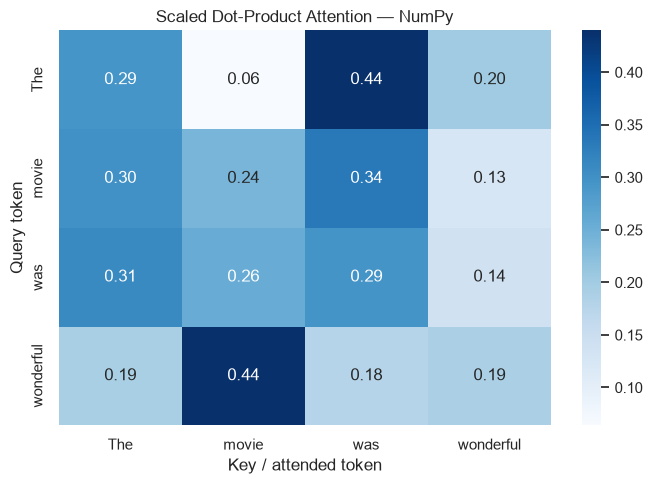

In [7]:
def softmax(x, axis=-1):
    x = x - np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)


def scaled_dot_product_attention(Q, K, V, mask=None):
    d_k = Q.shape[-1]
    scores = (Q @ K.T) / np.sqrt(d_k)
    if mask is not None:
        scores = scores + mask
    weights = softmax(scores, axis=-1)
    output = weights @ V
    return output, weights, scores


rng = np.random.default_rng(SEED)
tokens_demo = ["The", "movie", "was", "wonderful"]
Q = rng.normal(size=(4, 8))
K = rng.normal(size=(4, 8))
V = rng.normal(size=(4, 8))

attention_output, attention_weights, attention_scores = scaled_dot_product_attention(Q, K, V)

print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("V shape:", V.shape)
print("Score shape:", attention_scores.shape)
print("Attention output shape:", attention_output.shape)
print("Row sums:", np.round(attention_weights.sum(axis=1), 6))

plt.figure(figsize=(7, 5))
sns.heatmap(attention_weights, annot=True, fmt=".2f", cmap="Blues", xticklabels=tokens_demo, yticklabels=tokens_demo)
plt.title("Scaled Dot-Product Attention — NumPy")
plt.xlabel("Key / attended token")
plt.ylabel("Query token")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "task2_numpy_attention.png", dpi=150)
plt.show()

**Interpretation**

Each row corresponds to one query token and shows how its attention is distributed over all key tokens. The rows sum to one because softmax normalises the scores. The random values demonstrate the computation; they do not represent learned linguistic attention.

### 2.3 Why divide by the square root of the key dimension?

Without scaling, dot products tend to grow in magnitude as the vector dimension grows. Large scores can push softmax toward probabilities near zero or one, making gradients less useful. Scaling keeps score magnitudes more controlled.

In [8]:
scaling_rows = []
for d_k in [8, 64, 256]:
    q = rng.normal(size=(6, d_k))
    k = rng.normal(size=(6, d_k))
    raw_scores = q @ k.T
    scaled_scores = raw_scores / np.sqrt(d_k)
    raw_weights = softmax(raw_scores, axis=-1)
    scaled_weights = softmax(scaled_scores, axis=-1)
    raw_entropy = -np.sum(raw_weights * np.log(raw_weights + 1e-12), axis=1).mean()
    scaled_entropy = -np.sum(scaled_weights * np.log(scaled_weights + 1e-12), axis=1).mean()
    scaling_rows.append([d_k, np.std(raw_scores), np.std(scaled_scores), raw_entropy, scaled_entropy])

scaling_df = pd.DataFrame(scaling_rows, columns=["Key dimension", "Raw score SD", "Scaled score SD", "Raw mean entropy", "Scaled mean entropy"])
display(scaling_df.round(4))

,Key dimension,Raw score SD,Scaled score SD,Raw mean entropy,Scaled mean entropy
0,8,2.5492,0.9013,0.9119,1.5438
1,64,8.7664,1.0958,0.5074,1.5274
2,256,16.5293,1.0331,0.2707,1.4868


### 2.4 Luong dot attention

Luong dot attention compares decoder hidden states with encoder hidden states using a dot product. It resembles attention scoring, but the Query and Key/Value roles come from different sequence representations rather than from the same sequence.

In [9]:
def luong_dot_attention(query, encoder_states):
    # query: (1, hidden_size); encoder_states: (source_length, hidden_size)
    scores = encoder_states @ query.T
    weights = softmax(scores.squeeze(-1), axis=0)
    context = weights @ encoder_states
    return context, weights


query = rng.normal(size=(1, 8))
encoder_states = rng.normal(size=(5, 8))
luong_context, luong_weights = luong_dot_attention(query, encoder_states)

comparison = pd.DataFrame([["Self-attention", "Q, K and V from the same sequence", "Relates tokens within one sequence"],
                           ["Luong dot attention", "Decoder query compared with encoder states", "Lets a decoder focus on source states"]],
                          columns=["Method", "Where representations come from", "Main purpose"])
display(comparison)
print("Luong context shape:", luong_context.shape)
print("Luong weights:", np.round(luong_weights, 4))

,Method,Where representations come from,Main purpose
0,Self-attention,"Q, K and V from the same sequence",Relates tokens within one sequence
1,Luong dot attention,Decoder query compared with encoder states,Lets a decoder focus on source states


Luong context shape: (8,)
Luong weights: [0.0141 0.0892 0.5816 0.3126 0.0025]


### 2.5 Order-blindness demonstration

Self-attention alone does not encode absolute token positions. If token representations are permuted together, the output is permuted in the same way. Positional information is needed to distinguish word order.

In [10]:
X = rng.normal(size=(4, 8))
Wq = rng.normal(size=(8, 8))
Wk = rng.normal(size=(8, 8))
Wv = rng.normal(size=(8, 8))

def self_attention_from_X(X):
    return scaled_dot_product_attention(X @ Wq, X @ Wk, X @ Wv)[0]

original_output = self_attention_from_X(X)
permutation = np.array([2, 0, 3, 1])
shuffled_output = self_attention_from_X(X[permutation])

print("Output follows the same permutation:", np.allclose(shuffled_output, original_output[permutation], atol=1e-8))

Output follows the same permutation: True


### 2.6 Verify the NumPy calculation against DistilBERT

DistilBERT's attention layer projects hidden states into queries and keys. We recompute one attention head from those learned projections and compare the result with the model's returned attention weights.

In [12]:
verification_text = "The film was surprisingly good."
verification_inputs = tokenizer(verification_text, return_tensors="pt", truncation=True).to(DEVICE)

with torch.no_grad():
    model_outputs = encoder_model(**verification_inputs, output_attentions=True)

attention_layer = encoder_model.transformer.layer[0].attention
hidden_states = encoder_model.embeddings(verification_inputs["input_ids"])
q_proj = attention_layer.q_lin(hidden_states)
k_proj = attention_layer.k_lin(hidden_states)

num_heads = config.n_heads
head_dim = config.dim // num_heads
q_heads = q_proj.view(1, -1, num_heads, head_dim).transpose(1, 2)
k_heads = k_proj.view(1, -1, num_heads, head_dim).transpose(1, 2)

manual_scores = torch.matmul(q_heads, k_heads.transpose(-1, -2)) / np.sqrt(head_dim)
manual_weights = torch.softmax(manual_scores, dim=-1)
real_weights = model_outputs.attentions[0]

manual_head0 = manual_weights[0, 0].detach().cpu().numpy()
real_head0 = real_weights[0, 0].detach().cpu().numpy()

print("Manual shape:", manual_head0.shape)
print("Model shape:", real_head0.shape)
print("Numerical match:", np.allclose(manual_head0, real_head0, atol=1e-5))
print("Maximum absolute difference:", np.max(np.abs(manual_head0 - real_head0)))

Manual shape: (8, 8)
Model shape: (8, 8)
Numerical match: True
Maximum absolute difference: 0.0


---

# Task 3: Multi-Head Attention, Positional Encoding & Layer Normalization

### Objective
Inspect real attention heads, measure attention entropy, visualise positional encoding, and verify Layer Normalization with NumPy.

**Expected output:** Real attention heatmaps, entropy plot, positional-encoding heatmaps and a LayerNorm verification.

### 3.1 Multi-head attention

Multi-head attention runs several attention operations in parallel. Each head can learn different relationships, and the head outputs are concatenated and projected. DistilBERT uses multiple heads to represent different token-to-token patterns.

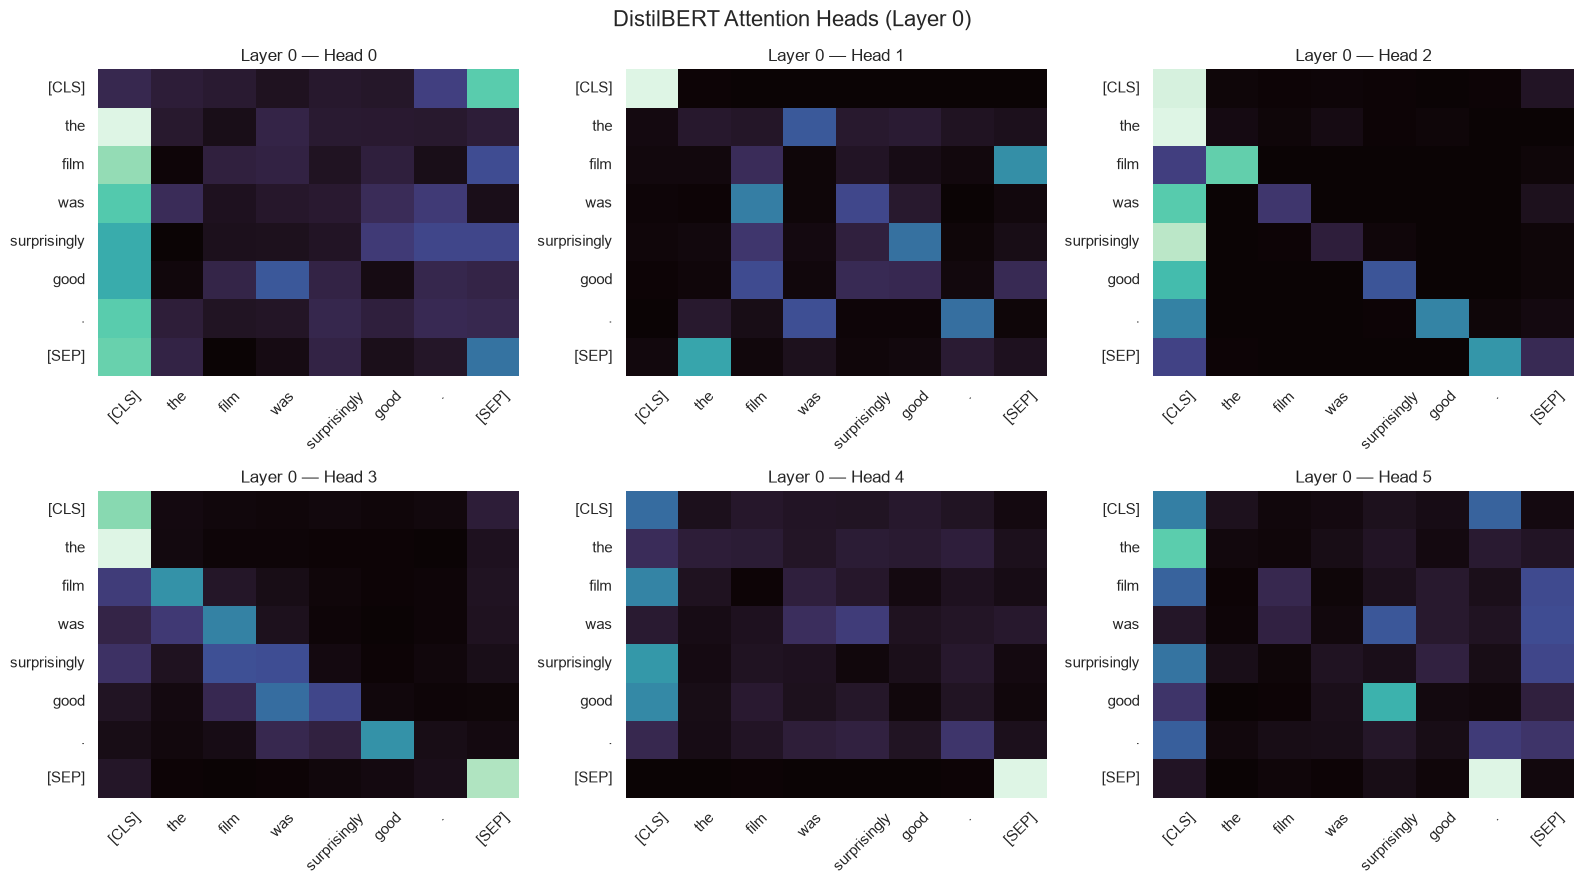

In [13]:
tokens = tokenizer.convert_ids_to_tokens(verification_inputs["input_ids"][0].cpu().tolist())
attn = real_weights[0].detach().cpu().numpy()  # heads x tokens x tokens

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for head_index, ax in enumerate(axes.flat):
    sns.heatmap(attn[head_index], cmap="mako", xticklabels=tokens, yticklabels=tokens, ax=ax, cbar=False)
    ax.set_title(f"Layer 0 — Head {head_index}")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)
    
plt.suptitle("DistilBERT Attention Heads (Layer 0)", fontsize=16)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "task3_attention_heads.png", dpi=150)
plt.show()

**Interpretation**

Compare heads rather than assuming every head has the same role. Some heads may focus strongly on nearby tokens or special tokens, while others spread attention more broadly. A heatmap is a useful inspection tool, but a single head should not be treated as a complete explanation of a model's decision.

### 3.2 Attention entropy by head

Entropy measures how spread out an attention distribution is. Lower entropy means a head concentrates more of its weight on a small number of tokens; higher entropy means the weights are more distributed.

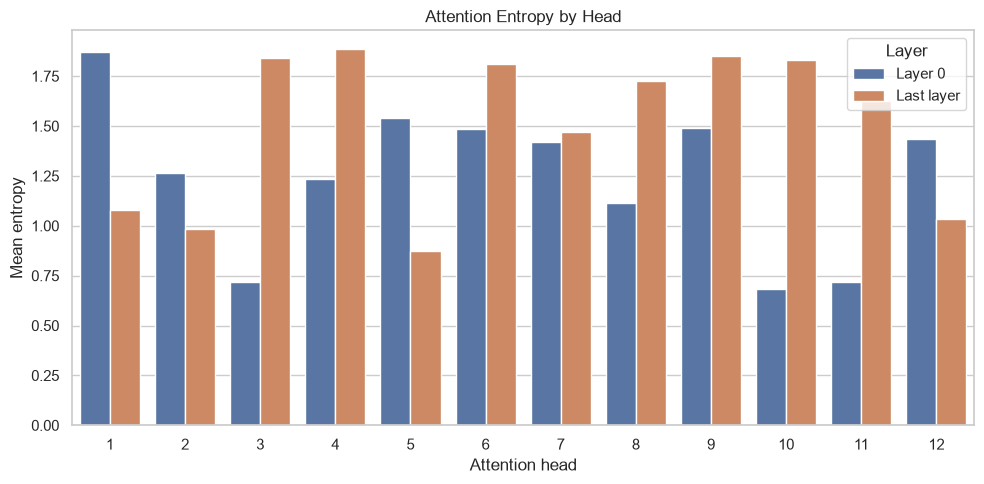

In [14]:
def attention_entropy(attention_array):
    return -(attention_array * np.log(attention_array + 1e-12)).sum(axis=-1).mean(axis=-1)

with torch.no_grad():
    entropy_outputs = encoder_model(**verification_inputs, output_attentions=True)

first_layer_attn = entropy_outputs.attentions[0][0].cpu().numpy()
last_layer_attn = entropy_outputs.attentions[-1][0].cpu().numpy()

entropy_df = pd.DataFrame({"Head": np.arange(1, first_layer_attn.shape[0] + 1),
                           "Layer 0": attention_entropy(first_layer_attn),
                           "Last layer": attention_entropy(last_layer_attn)}).melt("Head", var_name="Layer", value_name="Mean attention entropy")

plt.figure(figsize=(10, 5))
sns.barplot(data=entropy_df, x="Head", y="Mean attention entropy", hue="Layer")
plt.title("Attention Entropy by Head")
plt.xlabel("Attention head")
plt.ylabel("Mean entropy")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "task3_attention_entropy.png", dpi=150)
plt.show()

### Interpretation

- **Layer comparison:** Attention entropy varies across the 12 heads, showing that different heads distribute attention differently.
- **Entropy meaning:** Higher entropy indicates more distributed attention, while lower entropy indicates more concentrated attention. Several heads show noticeable differences between the first and last layers.

### 3.3 Sinusoidal positional encoding

Self-attention does not inherently know the order of tokens. Sinusoidal positional encodings add a position-dependent pattern to token representations, allowing the model to use order information.

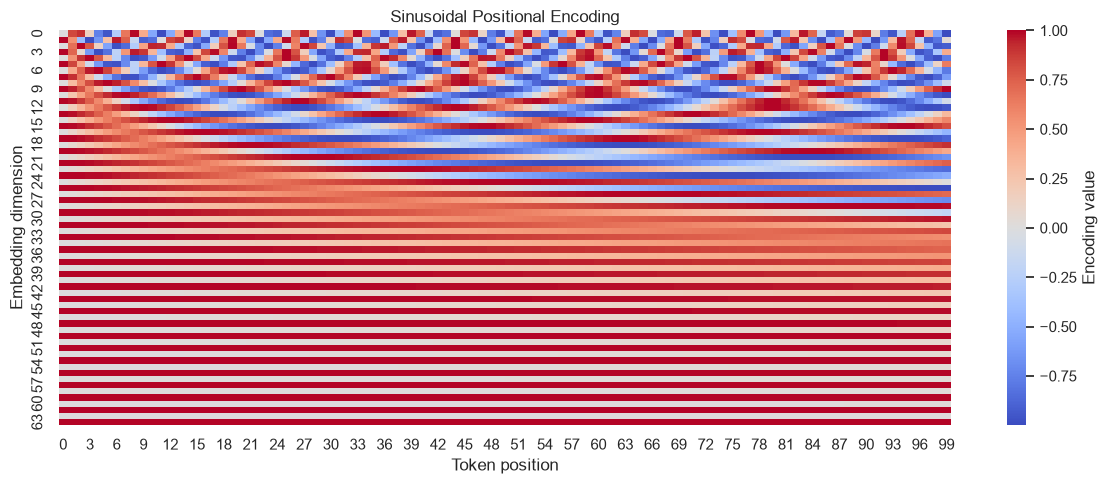

In [15]:
def sinusoidal_positional_encoding(max_positions, d_model):
    positions = np.arange(max_positions)[:, None]
    dimensions = np.arange(d_model)[None, :]
    angles = positions / np.power(10000, (2 * (dimensions // 2)) / d_model)
    encoding = np.zeros((max_positions, d_model))
    encoding[:, 0::2] = np.sin(angles[:, 0::2])
    encoding[:, 1::2] = np.cos(angles[:, 1::2])
    return encoding

pos_encoding = sinusoidal_positional_encoding(100, 64)

plt.figure(figsize=(12, 5))
sns.heatmap(pos_encoding.T, cmap="coolwarm", center=0, cbar_kws={"label":"Encoding value"})
plt.title("Sinusoidal Positional Encoding")
plt.xlabel("Token position")
plt.ylabel("Embedding dimension")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "task3_positional_encoding.png", dpi=150)
plt.show()

### Interpretation

- **Pattern:** The heatmap shows repeating sine and cosine patterns across token positions and embedding dimensions.
- **Purpose:** These unique patterns help the Transformer represent token positions and understand the order of words in a sequence.

### 3.4 Same word at two positions

The cosine similarity experiment shows how adding different positional vectors changes the representation of the same token at different positions.

In [16]:
def cosine_similarity(a, b):
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))

word_vector = rng.normal(size=64)
pos_a, pos_b = 3, 30
similarity_without_pe = cosine_similarity(word_vector, word_vector)
similarity_with_pe = cosine_similarity(word_vector + pos_encoding[pos_a], word_vector + pos_encoding[pos_b])
print(f"Cosine similarity without positional encoding: {similarity_without_pe:.4f}")
print(f"Cosine similarity with positional encoding:    {similarity_with_pe:.4f}")

Cosine similarity without positional encoding: 1.0000
Cosine similarity with positional encoding:    0.8369


### 3.5 DistilBERT learned position embeddings

Unlike the original sinusoidal scheme, DistilBERT uses learned position embeddings. We inspect cosine similarity between the first 64 position vectors.

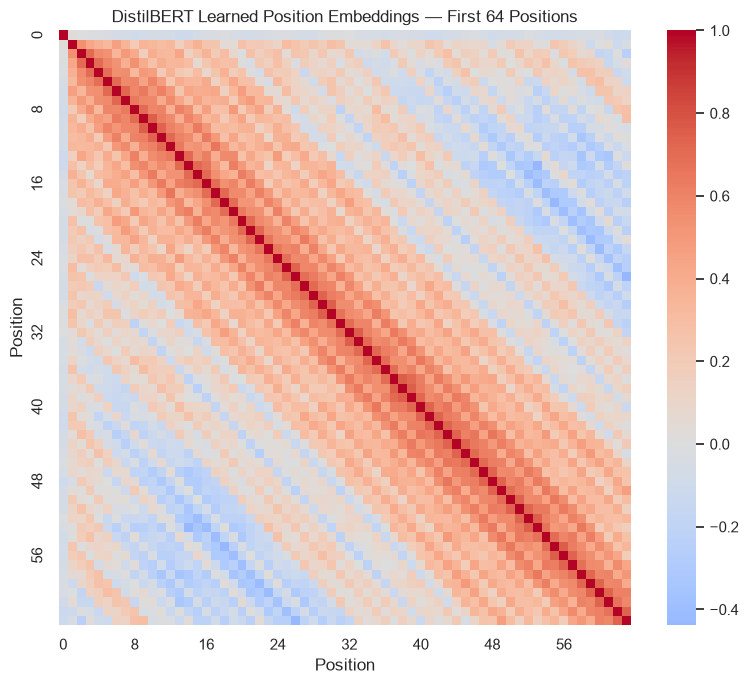

Position embedding table shape: (512, 768)
Maximum position embeddings: 512


In [17]:
position_embeddings = encoder_model.embeddings.position_embeddings.weight.detach().cpu().numpy()
position_subset = position_embeddings[:64]
norms = np.linalg.norm(position_subset, axis=1, keepdims=True)
position_normalized = position_subset / np.maximum(norms, 1e-12)
position_similarity = position_normalized @ position_normalized.T

plt.figure(figsize=(8, 7))
sns.heatmap(position_similarity, cmap="coolwarm", center=0, xticklabels=8, yticklabels=8)
plt.title("DistilBERT Learned Position Embeddings — First 64 Positions")
plt.xlabel("Position")
plt.ylabel("Position")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "task3_learned_position_similarity.png", dpi=150)
plt.show()

print("Position embedding table shape:", tuple(encoder_model.embeddings.position_embeddings.weight.shape))
print("Maximum position embeddings:", config.max_position_embeddings)

### Interpretation

- **Similarity:** The heatmap shows stronger similarity between nearby positions, visible as the red diagonal pattern.
- **Embedding dimensions:** The positional embedding table has a shape of `(512, 768)`, supporting sequences of up to 512 token positions.

### 3.6 Layer Normalization from scratch

LayerNorm normalises features within each individual sample/token and then applies learned scale (gamma) and shift (beta). BatchNorm instead uses batch-level statistics during training, so the two methods behave differently.

In [19]:
def numpy_layer_norm(x, gamma, beta, eps=1e-5):
    mean = x.mean(axis=-1, keepdims=True)
    variance = x.var(axis=-1, keepdims=True)
    normalized = (x - mean) / np.sqrt(variance + eps)
    return normalized * gamma + beta

test_array = rng.normal(size=(3, 8)).astype(np.float32)
gamma = rng.normal(size=8).astype(np.float32)
beta = rng.normal(size=8).astype(np.float32)

numpy_result = numpy_layer_norm(test_array, gamma, beta)
torch_layer_norm = torch.nn.LayerNorm(8, eps=1e-5)
with torch.no_grad():
    torch_layer_norm.weight.copy_(torch.tensor(gamma))
    torch_layer_norm.bias.copy_(torch.tensor(beta))
torch_result = torch_layer_norm(torch.tensor(test_array)).detach().numpy()

print("NumPy result shape:", numpy_result.shape)
print("PyTorch result shape:", torch_result.shape)
print("Matches torch.nn.LayerNorm:", np.allclose(numpy_result, torch_result, atol=1e-5))
print("Maximum absolute difference:", np.max(np.abs(numpy_result - torch_result)))

layer_norm_params = [(n, tuple(p.shape)) for n, p in encoder_model.named_parameters()
                     if "layer_norm" in n.lower()][:6]
display(pd.DataFrame(layer_norm_params, columns=["LayerNorm parameter", "Shape"]))

NumPy result shape: (3, 8)
PyTorch result shape: (3, 8)
Matches torch.nn.LayerNorm: True
Maximum absolute difference: 2.3841858e-07


,LayerNorm parameter,Shape
0,transformer.layer.0.sa_layer_norm.weight,"(768,)"
1,transformer.layer.0.sa_layer_norm.bias,"(768,)"
2,transformer.layer.0.output_layer_norm.weight,"(768,)"
3,transformer.layer.0.output_layer_norm.bias,"(768,)"
4,transformer.layer.1.sa_layer_norm.weight,"(768,)"
5,transformer.layer.1.sa_layer_norm.bias,"(768,)"


**LayerNorm vs BatchNorm**

| Layer Normalization | Batch Normalization |
|---|---|
| Normalises features within each sample/token | Normalises features using batch statistics during training |
| Works naturally with variable sequence lengths | Batch composition can affect its statistics |
| Common in Transformer blocks | Common in convolutional and some feed-forward networks |

### 3.7 Encoder structure and parameter distribution

A Transformer encoder block contains self-attention, residual connections, LayerNorm and a feed-forward network. DistilBERT is an encoder-only model and does not include a text-generation decoder.

In [20]:
print(encoder_model)

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=Tru

,Component,Count
2,Feed-forward,28334592
1,Embeddings,23835648
0,Attention,14174208
3,LayerNorm,18432


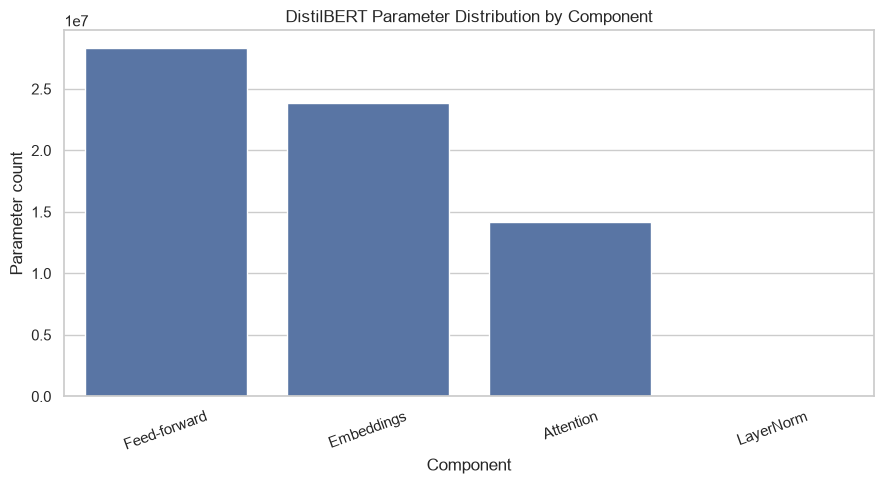

In [21]:
def parameter_group(name):
    name_lower = name.lower()
    if "embeddings" in name_lower:
        return "Embeddings"
    if any(x in name_lower for x in ["q_lin", "k_lin", "v_lin", "out_lin"]):
        return "Attention"
    if any(x in name_lower for x in ["ffn", "lin1", "lin2"]):
        return "Feed-forward"
    if "layer_norm" in name_lower:
        return "LayerNorm"
    return "Other / pooler"

parameter_rows = [(name, param.numel(), parameter_group(name))
                  for name, param in encoder_model.named_parameters()]
parameter_df = pd.DataFrame(parameter_rows, columns=["Parameter", "Count", "Component"])
component_counts = parameter_df.groupby("Component", as_index=False)["Count"].sum().sort_values("Count", ascending=False)
display(component_counts)

plt.figure(figsize=(9, 5))
sns.barplot(data=component_counts, x="Component", y="Count")
plt.title("DistilBERT Parameter Distribution by Component")
plt.xlabel("Component")
plt.ylabel("Parameter count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "task3_parameter_distribution.png", dpi=150)
plt.show()

### Interpretation

The bar chart shows that **feed-forward layers** contain the most parameters, followed by embeddings and attention layers. Layer Normalization has very few parameters in comparison, indicating that most of DistilBERT's parameters are concentrated in its main processing components.

---

# Task 4: Transformer Encoder & Masked Self-Attention

### Objective
Inspect bidirectional encoder attention, causal masking in GPT-2, and padding masks in DistilBERT.

**Expected output:** Fill-mask predictions, attention comparisons, a NumPy causal-mask heatmap and a padding-versus-causal comparison.

### 4.1 Fill-mask pipeline

The fill-mask pipeline predicts candidate tokens for a masked position using context on both sides of the mask.

In [22]:
fill_mask_pipe = pipeline("fill-mask", model="distilbert-base-uncased", device=0 if DEVICE == "cuda" else -1)
masked_sentences = ["The movie was [MASK] and entertaining.",
                    "She went to the [MASK] to borrow a book.",
                    "A good night's sleep is important for your [MASK]."]
fill_mask_rows = []
for sentence in masked_sentences:
    predictions = fill_mask_pipe(sentence, top_k=3)
    for rank, prediction in enumerate(predictions, start=1):
        fill_mask_rows.append([sentence, rank, prediction["token_str"], round(prediction["score"], 4)])
        
display(pd.DataFrame(fill_mask_rows, columns=["Sentence", "Rank", "Predicted token", "Score"]))

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

,Sentence,Rank,Predicted token,Score
0,The movie was [MASK] and entertaining.,1,fun,0.0890
1,The movie was [MASK] and entertaining.,2,entertaining,0.0611
2,The movie was [MASK] and entertaining.,3,funny,0.0386
3,She went to the [MASK] to borrow a book.,1,library,0.2835
4,She went to the [MASK] to borrow a book.,2,bookstore,0.1900
5,She went to the [MASK] to borrow a book.,3,attic,0.0335
6,A good night's sleep is important for your [MA...,1,survival,0.0462
7,A good night's sleep is important for your [MA...,2,health,0.0454
8,A good night's sleep is important for your [MA...,3,safety,0.0365


### 4.2 Bidirectional attention in DistilBERT

An encoder can attend to tokens on both the left and right of the current token. This is useful for understanding a sentence using its full context.

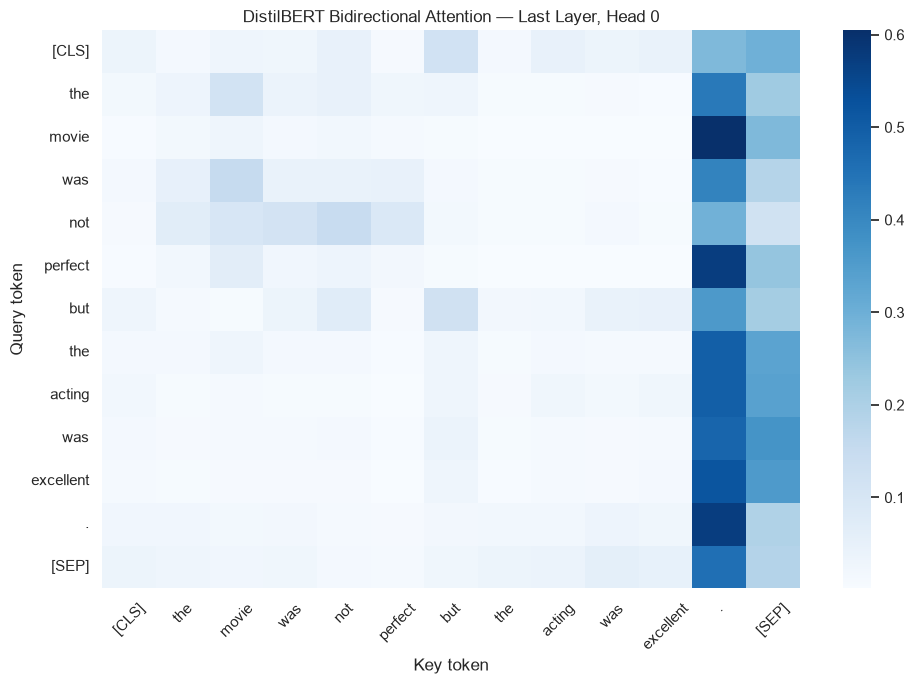

In [23]:
encoder_text = "The movie was not perfect but the acting was excellent."
encoder_inputs = tokenizer(encoder_text, return_tensors="pt", truncation=True).to(DEVICE)
with torch.no_grad():
    encoder_attention_outputs = encoder_model(**encoder_inputs, output_attentions=True)

encoder_tokens = tokenizer.convert_ids_to_tokens(encoder_inputs["input_ids"][0].cpu().tolist())
encoder_head_attention = encoder_attention_outputs.attentions[-1][0, 0].cpu().numpy()

plt.figure(figsize=(10, 7))
sns.heatmap(encoder_head_attention, cmap="Blues", xticklabels=encoder_tokens, yticklabels=encoder_tokens)
plt.title("DistilBERT Bidirectional Attention — Last Layer, Head 0")
plt.xlabel("Key token")
plt.ylabel("Query token")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "task4_bidirectional_attention.png", dpi=150)
plt.show()

### Interpretation

The heatmap shows that DistilBERT uses **bidirectional self-attention**, allowing each token to attend to both earlier and later tokens in the sentence. Stronger attention to certain tokens, such as punctuation and important words, indicates how the model distributes attention across the input.

### 4.3 Build a causal mask in NumPy

A causal mask adds negative infinity above the diagonal before softmax. Those future positions receive zero probability, while each token can attend to itself and earlier tokens.

Causal mask:
[[  0. -inf -inf -inf -inf -inf]
 [  0.   0. -inf -inf -inf -inf]
 [  0.   0.   0. -inf -inf -inf]
 [  0.   0.   0.   0. -inf -inf]
 [  0.   0.   0.   0.   0. -inf]
 [  0.   0.   0.   0.   0.   0.]]

Row sums: [1. 1. 1. 1. 1. 1.]
Maximum above-diagonal attention: 0.0


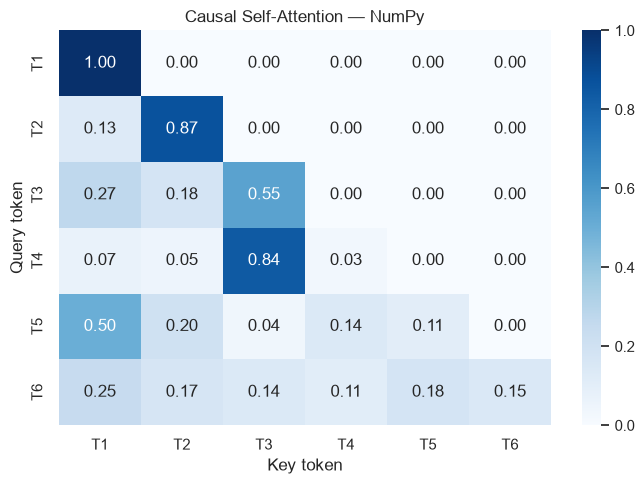

In [24]:
sequence_length = 6
causal_mask = np.triu(np.full((sequence_length, sequence_length), -np.inf), k=1)
causal_mask[np.tril_indices(sequence_length)] = 0

mask_demo_scores = rng.normal(size=(sequence_length, sequence_length))
masked_weights = softmax(mask_demo_scores + causal_mask, axis=-1)

print("Causal mask:")
print(causal_mask)
print("\nRow sums:", np.round(masked_weights.sum(axis=1), 6))
print("Maximum above-diagonal attention:", np.triu(masked_weights, k=1).max())

plt.figure(figsize=(7, 5))
sns.heatmap(masked_weights, annot=True, fmt=".2f", cmap="Blues", xticklabels=[f"T{i+1}" for i in range(sequence_length)], yticklabels=[f"T{i+1}" for i in range(sequence_length)])
plt.title("Causal Self-Attention — NumPy")
plt.xlabel("Key token")
plt.ylabel("Query token")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "task4_numpy_causal_mask.png", dpi=150)
plt.show()

### Interpretation

The causal mask assigns `-inf` to future token positions, making their attention weights zero after softmax. Each row sums to 1, and the maximum attention above the diagonal is 0, confirming that future tokens cannot be attended to.

**Why use negative infinity before softmax?**

Softmax of negative infinity is zero, so a forbidden future position receives no attention probability. If we zeroed the weights after softmax, the remaining weights would no longer sum to one unless we renormalised them.

### 4.4 Causal attention in GPT-2

GPT-2 is decoder-only. Its causal mask prevents each token from using information from future tokens.

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

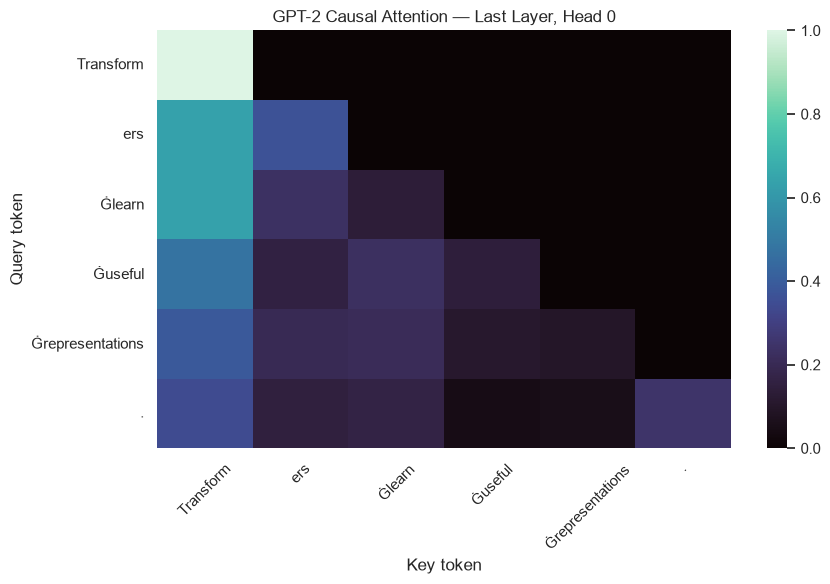

Maximum attention above diagonal: 0.0
Causal-mask check passed: True


In [25]:
gpt2_tokenizer = AutoTokenizer.from_pretrained(GPT2_MODEL_ID)
if gpt2_tokenizer.pad_token is None:
    gpt2_tokenizer.pad_token = gpt2_tokenizer.eos_token

gpt2_model = AutoModelForCausalLM.from_pretrained(GPT2_MODEL_ID, attn_implementation="eager").to(DEVICE)
gpt2_model.eval()

gpt_text = "Transformers learn useful representations."
gpt_inputs = gpt2_tokenizer(gpt_text, return_tensors="pt").to(DEVICE)
with torch.no_grad():
    gpt_outputs = gpt2_model(**gpt_inputs, output_attentions=True)

gpt_tokens = gpt2_tokenizer.convert_ids_to_tokens(gpt_inputs["input_ids"][0].cpu().tolist())
gpt_attention = gpt_outputs.attentions[-1][0, 0].cpu().numpy()

plt.figure(figsize=(9, 6))
sns.heatmap(gpt_attention, cmap="mako", xticklabels=gpt_tokens, yticklabels=gpt_tokens)
plt.title("GPT-2 Causal Attention — Last Layer, Head 0")
plt.xlabel("Key token")
plt.ylabel("Query token")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "task4_gpt2_causal_attention.png", dpi=150)
plt.show()

future_attention_max = np.triu(gpt_attention, k=1).max()
print("Maximum attention above diagonal:", future_attention_max)
print("Causal-mask check passed:", future_attention_max < 1e-6)

### Interpretation

The heatmap shows that GPT-2 uses **causal attention**, where each token can attend only to itself and previous tokens, not future tokens. The causal-mask check passed, confirming that all attention weights above the diagonal are zero.

### 4.5 Padding mask vs causal mask

Padding masks prevent the model from treating padded positions as real tokens. Causal masks prevent a decoder token from looking at future tokens. They solve different problems.

In [26]:
padding_batch = tokenizer(["Short sentence.", "This is a somewhat longer sentence for the batch."], padding=True, return_tensors="pt").to(DEVICE)
with torch.no_grad():
    padding_outputs = encoder_model(**padding_batch, output_attentions=True)

print("Attention mask:")
print(padding_batch["attention_mask"].cpu().numpy())
print("\nAttention shape:", tuple(padding_outputs.attentions[0].shape))

mask_comparison = pd.DataFrame([["Padding mask", "Ignore padding tokens", "Usually based on attention_mask", "Encoder and decoder batches"],
                                ["Causal mask", "Prevent access to future tokens", "Lower-triangular allowed region", "Autoregressive decoder"]],
                               columns=["Mask", "Purpose", "Pattern", "Typical use"])
display(mask_comparison)

Attention mask:
[[1 1 1 1 1 0 0 0 0 0 0 0]
 [1 1 1 1 1 1 1 1 1 1 1 1]]

Attention shape: (2, 12, 12, 12)


,Mask,Purpose,Pattern,Typical use
0,Padding mask,Ignore padding tokens,Usually based on attention_mask,Encoder and decoder batches
1,Causal mask,Prevent access to future tokens,Lower-triangular allowed region,Autoregressive decoder


---

# Task 5: Cross-Attention, Decoder Architecture & Inference

### Objective
Use T5 for translation and summarisation, inspect cross-attention, reproduce greedy GPT-2 decoding, compare decoding strategies and measure KV-cache timing.

**Expected output:** Translation and summary outputs, cross-attention heatmap, matching manual greedy decoding, decoding comparison and cache timing.

### 5.1 Decoder architecture

The original Transformer decoder block applies masked self-attention, then cross-attention to encoder outputs, followed by a feed-forward network. Residual connections and normalisation surround these sublayers. GPT-2 is decoder-only and omits cross-attention; T5 uses an encoder-decoder architecture.

### 5.2 Cross-attention and Luong attention

In cross-attention, Queries come from the decoder while Keys and Values come from the encoder output. This allows the decoder to consult the source sequence while producing each target token, similar in purpose to Luong attention.

### 5.3 T5 translation and summarisation

T5 uses a text-to-text format. Task prefixes such as `translate English to French:` tell the model what transformation to perform.

In [29]:
t5_tokenizer = T5Tokenizer.from_pretrained(T5_MODEL_ID)
t5_model = T5ForConditionalGeneration.from_pretrained(T5_MODEL_ID, attn_implementation="eager").to(DEVICE)
t5_model.eval()
translation_sentences = ["The house is small.",
                         "Machine learning can help people analyse data.",
                         "The weather is pleasant today."]
translation_results = []

for sentence in translation_sentences:
    inputs = t5_tokenizer("translate English to French: " + sentence,
                          return_tensors="pt",
                          truncation=True).to(DEVICE)

    with torch.no_grad():
        output_ids = t5_model.generate(**inputs, max_new_tokens=64)

    translated_text = t5_tokenizer.decode(output_ids[0], skip_special_tokens=True)
    translation_results.append(translated_text)

display(pd.DataFrame({"English": translation_sentences,
                      "French": translation_results}))

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

,English,French
0,The house is small.,La maison est petite.
1,Machine learning can help people analyse data.,L'apprentissage en machine peut aider les gens...
2,The weather is pleasant today.,Le temps est agréable aujourd'hui.


### 5.4 Summarise a real passage

Replace the example paragraph below with a paragraph from a real article or source you choose. Keep the source noted in your report if you use an external passage.

In [31]:
real_paragraph = ("Artificial intelligence is transforming many industries. "
                  "Machine learning models can analyse large amounts of data and "
                  "help people make better decisions. However, their results depend "
                  "on the quality of the data and the way the systems are evaluated. "
                  "Organisations should check accuracy, privacy, fairness and "
                  "reliability before using AI in important decisions. "
                  "Human review remains valuable when an incorrect output could cause harm.")

inputs = t5_tokenizer("summarize: " + real_paragraph, return_tensors="pt", truncation=True).to(DEVICE)

with torch.no_grad():
    summary_ids = t5_model.generate(**inputs, max_new_tokens=60, min_new_tokens=20, do_sample=False)

summary_result = t5_tokenizer.decode(summary_ids[0],skip_special_tokens=True)

print("Input words:", len(real_paragraph.split()))
print("Summary words:", len(summary_result.split()))
print("\nSummary:", summary_result)

Input words: 63
Summary words: 16

Summary: artificial intelligence is changing industries. a number of industries are using AI to make better decisions.


### 5.5 Extract and plot cross-attention

The last T5 decoder layer contains cross-attention from output tokens to input tokens. Averaging across heads gives a compact view of which source positions are associated with each target position.

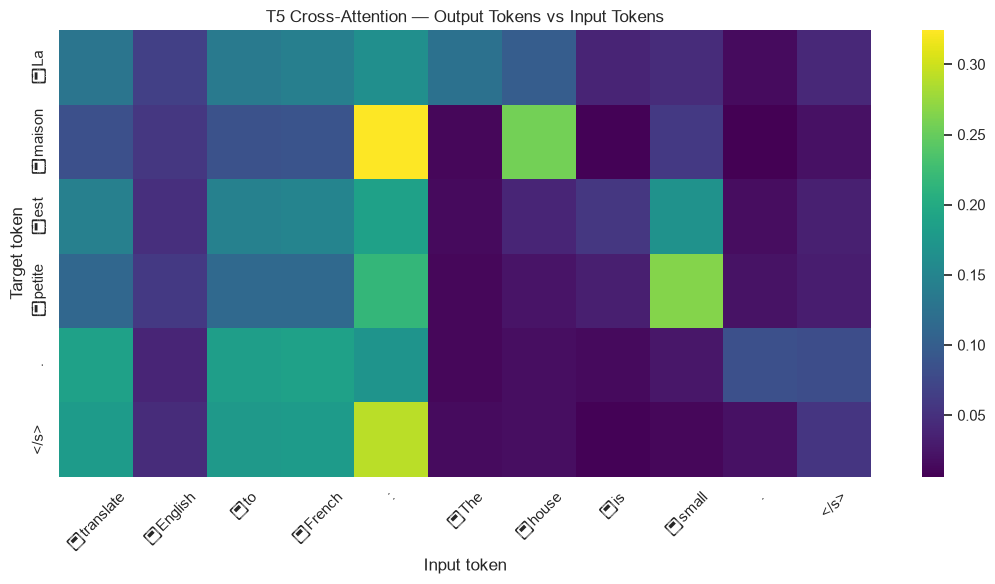

In [32]:
source_text = "translate English to French: The house is small."
target_text = "La maison est petite."

source_inputs = t5_tokenizer(source_text, return_tensors="pt").to(DEVICE)
target_labels = t5_tokenizer(target_text, return_tensors="pt").input_ids.to(DEVICE)

with torch.no_grad():
    t5_attention_outputs = t5_model(input_ids=source_inputs["input_ids"], attention_mask=source_inputs["attention_mask"], labels=target_labels, output_attentions=True, return_dict=True)

cross_attention = t5_attention_outputs.cross_attentions[-1][0].mean(dim=0).cpu().numpy()
source_tokens = t5_tokenizer.convert_ids_to_tokens(source_inputs["input_ids"][0].cpu().tolist())
target_tokens = t5_tokenizer.convert_ids_to_tokens(target_labels[0].cpu().tolist())

plt.figure(figsize=(11, 6))
sns.heatmap(cross_attention, cmap="viridis", xticklabels=source_tokens, yticklabels=target_tokens)
plt.title("T5 Cross-Attention — Output Tokens vs Input Tokens")
plt.xlabel("Input token")
plt.ylabel("Target token")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "task5_t5_cross_attention.png", dpi=150)
plt.show()

**Interpretation**

Check whether content words in the French output place attention on related English source words. Alignment is not always one-to-one: subword tokenisation, punctuation and multi-word expressions can spread attention across several positions.

### 5.6 Manual greedy decoding

Autoregressive generation produces one next token at a time and appends it to the existing sequence. Greedy decoding selects the token with the highest next-token logit at every step.

In [33]:
prompt = "Artificial intelligence will"
manual_input_ids = gpt2_tokenizer(prompt, return_tensors="pt").input_ids.to(DEVICE)

with torch.no_grad():
    generated_ids = manual_input_ids.clone()
    for _ in range(20):
        next_logits = gpt2_model(input_ids=generated_ids).logits[:, -1, :]
        next_token = torch.argmax(next_logits, dim=-1, keepdim=True)
        generated_ids = torch.cat([generated_ids, next_token], dim=-1)

manual_text = gpt2_tokenizer.decode(generated_ids[0], skip_special_tokens=True)
library_ids = gpt2_model.generate(manual_input_ids, max_new_tokens=20, do_sample=False, use_cache=True, pad_token_id=gpt2_tokenizer.eos_token_id)
library_text = gpt2_tokenizer.decode(library_ids[0], skip_special_tokens=True)

print("Manual greedy decoding:")
print(manual_text)
print("\nmodel.generate() greedy decoding:")
print(library_text)
print("\nOutputs identical:", torch.equal(generated_ids.cpu(), library_ids.cpu()))

Manual greedy decoding:
Artificial intelligence will be able to do things like search for and find people, and to do things like find out who

model.generate() greedy decoding:
Artificial intelligence will be able to do things like search for and find people, and to do things like find out who

Outputs identical: True


### 5.7 Compare decoding strategies

Greedy decoding is deterministic, beam search explores multiple candidate sequences, and sampling introduces controlled randomness. Temperature adjusts how sharp the probability distribution is; top-k and top-p restrict which tokens may be sampled.

In [34]:
def generate_text(prompt, seed, **generation_kwargs):
    torch.manual_seed(seed)
    inputs = gpt2_tokenizer(prompt, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        output_ids = gpt2_model.generate(**inputs, max_new_tokens=40, pad_token_id=gpt2_tokenizer.eos_token_id, **generation_kwargs)
    return gpt2_tokenizer.decode(output_ids[0], skip_special_tokens=True)

decoding_rows = [["Greedy", "do_sample=False", generate_text(prompt, SEED, do_sample=False)],
                 ["Beam search", "num_beams=5", generate_text(prompt, SEED, do_sample=False, num_beams=5, early_stopping=True)],
                 ["Temperature 0.7 (seed 42)", "sampling, temperature=0.7", generate_text(prompt, 42, do_sample=True, temperature=0.7)],
                 ["Temperature 0.7 (seed 7)", "sampling, temperature=0.7", generate_text(prompt, 7, do_sample=True, temperature=0.7)],
                 ["Temperature 1.5 (seed 42)", "sampling, temperature=1.5", generate_text(prompt, 42, do_sample=True, temperature=1.5)],
                 ["Temperature 1.5 (seed 7)", "sampling, temperature=1.5", generate_text(prompt, 7, do_sample=True, temperature=1.5)],
                 ["Top-k + top-p", "top_k=50, top_p=0.9", generate_text(prompt, 21, do_sample=True, top_k=50, top_p=0.9)]]
display(pd.DataFrame(decoding_rows, columns=["Strategy", "Settings", "Generated text"]))

,Strategy,Settings,Generated text
0,Greedy,do_sample=False,Artificial intelligence will be able to do thi...
1,Beam search,num_beams=5,Artificial intelligence will be the next big t...
2,Temperature 0.7 (seed 42),"sampling, temperature=0.7",Artificial intelligence will be used to create...
3,Temperature 0.7 (seed 7),"sampling, temperature=0.7",Artificial intelligence will only be able to f...
4,Temperature 1.5 (seed 42),"sampling, temperature=1.5",Artificial intelligence will continue to expan...
5,Temperature 1.5 (seed 7),"sampling, temperature=1.5",Artificial intelligence will only reach some a...
6,Top-k + top-p,"top_k=50, top_p=0.9",Artificial intelligence will enable us to make...


**Interpretation**

- Greedy decoding is repeatable but can produce repetitive or locally optimal text.
- Beam search compares several candidate continuations and is not the same as random sampling.
- Higher temperature generally makes sampling more varied; lower temperature concentrates probability on likely tokens.
- Top-k limits sampling to the k highest-probability tokens, while top-p selects a probability mass dynamically.

### 5.8 KV-cache speed-up

With caching enabled, the model reuses earlier key/value states instead of recomputing them for every generated token. Timing is hardware-dependent, so this experiment reports measured values rather than assuming caching is always a fixed multiple faster.

In [35]:
cache_prompt = "Transformers are useful because"
cache_inputs = gpt2_tokenizer(cache_prompt, return_tensors="pt").to(DEVICE)

def time_generation(use_cache, repeats=3):
    durations = []
    for _ in range(repeats):
        start = time.perf_counter()
        with torch.no_grad():
            gpt2_model.generate(**cache_inputs, max_new_tokens=100, do_sample=False, use_cache=use_cache, pad_token_id=gpt2_tokenizer.eos_token_id)
        durations.append(time.perf_counter() - start)
    return float(np.mean(durations)), durations

# Warm-up
with torch.no_grad():
    gpt2_model.generate(**cache_inputs, max_new_tokens=5, use_cache=True, pad_token_id=gpt2_tokenizer.eos_token_id)

cache_time, cache_runs = time_generation(True)
no_cache_time, no_cache_runs = time_generation(False)
speedup = no_cache_time / cache_time if cache_time > 0 else np.nan

display(pd.DataFrame([["use_cache=True", cache_time, cache_runs],
                      ["use_cache=False", no_cache_time, no_cache_runs]],
                     columns=["Setting", "Mean time (seconds)", "Individual run times"]))
print(f"Measured speed-up from caching: {speedup:.2f}x")

,Setting,Mean time (seconds),Individual run times
0,use_cache=True,18.230428,"[13.538793699990492, 12.94054939999478, 28.211..."
1,use_cache=False,29.473389,"[28.274650499995914, 28.076409300003434, 32.06..."


Measured speed-up from caching: 1.62x


### 5.9 Model-family comparison

In [36]:
family_comparison = pd.DataFrame([["DistilBERT", "Encoder-only", "Bidirectional self-attention", "Learned absolute positions", "No (classification / representation)", "Sentiment and masked-token inspection"],
                                  ["GPT-2", "Decoder-only", "Causal masked self-attention", "Learned absolute positions", "Yes", "Autoregressive text generation"],
                                  ["T5-small", "Encoder-decoder", "Encoder self-attention + decoder causal self-attention + cross-attention", "Relative position bias", "Yes", "Translation and summarisation"]],
                                 columns=["Model", "Family", "Attention type(s)", "Position scheme", "Can generate text?", "Notebook example"])
display(family_comparison)

,Model,Family,Attention type(s),Position scheme,Can generate text?,Notebook example
0,DistilBERT,Encoder-only,Bidirectional self-attention,Learned absolute positions,No (classification / representation),Sentiment and masked-token inspection
1,GPT-2,Decoder-only,Causal masked self-attention,Learned absolute positions,Yes,Autoregressive text generation
2,T5-small,Encoder-decoder,Encoder self-attention + decoder causal self-a...,Relative position bias,Yes,Translation and summarisation


---

# Task 6: Mini Application, Evaluation & Disadvantages in Practice

### Objective
Evaluate the pretrained sentiment model on 200 IMDb reviews, measure truncation and latency, check factual generation, and combine the models in a reusable text toolkit.

**Expected output:** Classification metrics and confusion matrix, length/time plots, hallucination observations, toolkit tests and a personal reflection.

### 6.1 Load the 200-review IMDb sample

The practical uses a fixed, reproducible sample from the public IMDb test split. Labels are `0 = negative` and `1 = positive`.

In [38]:
imdb_ds = load_dataset("stanfordnlp/imdb", split="test").shuffle(seed=SEED).select(range(200))
imdb_df = pd.DataFrame(imdb_ds)
imdb_df["review_tokens"] = imdb_df["text"].apply(lambda x: len(tokenizer(x, truncation=False)["input_ids"]))

print("Dataset shape:", imdb_df.shape)
display(imdb_df[["text", "label", "review_tokens"]].head())
print("\nLabel distribution:")
display(imdb_df["label"].value_counts().rename(index={0:"Negative", 1:"Positive"}).to_frame("count"))

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (632 > 512). Running this sequence through the model will result in indexing errors


Dataset shape: (200, 3)


,text,label,review_tokens
0,<br /><br />When I unsuspectedly rented A Thou...,1,437
1,This is the latest entry in the long series of...,1,240
2,This movie was so frustrating. Everything seem...,0,163
3,"I was truly and wonderfully surprised at ""O' B...",1,145
4,This movie spends most of its time preaching t...,0,111



Label distribution:


,count
label,
Negative,104
Positive,96


### 6.2 Evaluate sentiment at different truncation lengths

We use the same 200 reviews at maximum lengths 64, 128, 256 and 512. The pipeline truncates longer reviews, and each run records its metrics and elapsed time.

In [39]:
def evaluate_sentiment(max_length, batch_size=16):
    start = time.perf_counter()
    predictions = sentiment_pipe(imdb_df["text"].tolist(), batch_size=batch_size, truncation=True, max_length=max_length)
    elapsed = time.perf_counter() - start
    y_true = imdb_df["label"].to_numpy()
    y_pred = np.array([1 if item["label"].upper() == "POSITIVE" else 0 for item in predictions])
    metrics = {"max_length": max_length,
               "accuracy": accuracy_score(y_true, y_pred),
               "precision": precision_score(y_true, y_pred, zero_division=0),
               "recall": recall_score(y_true, y_pred, zero_division=0),
               "f1": f1_score(y_true, y_pred, zero_division=0),
               "time_seconds": elapsed,
               "predictions": y_pred}
    return metrics

evaluation_runs = [evaluate_sentiment(length) for length in [64, 128, 256, 512]]
evaluation_df = pd.DataFrame([{k:v for k,v in run.items() if k != "predictions"} for run in evaluation_runs])
display(evaluation_df.round(4))

,max_length,accuracy,precision,recall,f1,time_seconds
0,64,0.750,0.7674,0.6875,0.7253,49.3969
1,128,0.775,0.7576,0.7812,0.7692,57.8754
2,256,0.840,0.8636,0.7917,0.8261,83.1745
3,512,0.870,0.8889,0.8333,0.8602,173.7256


### 6.3 Accuracy vs truncation length

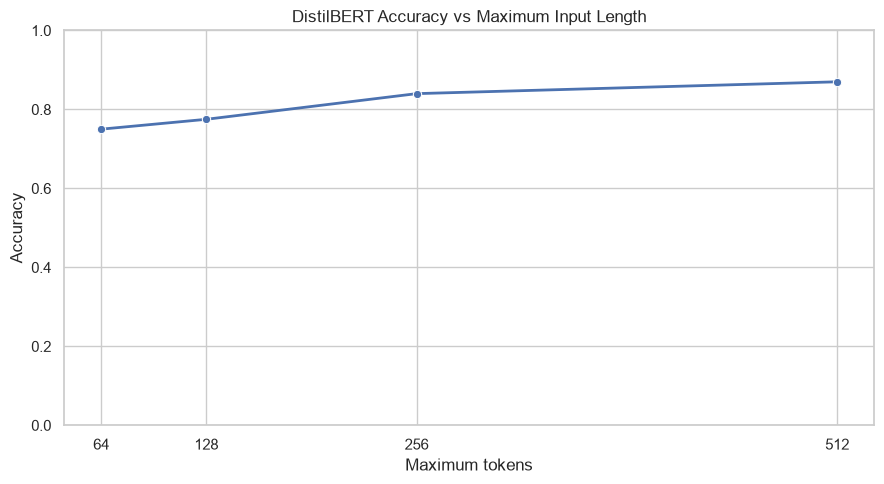

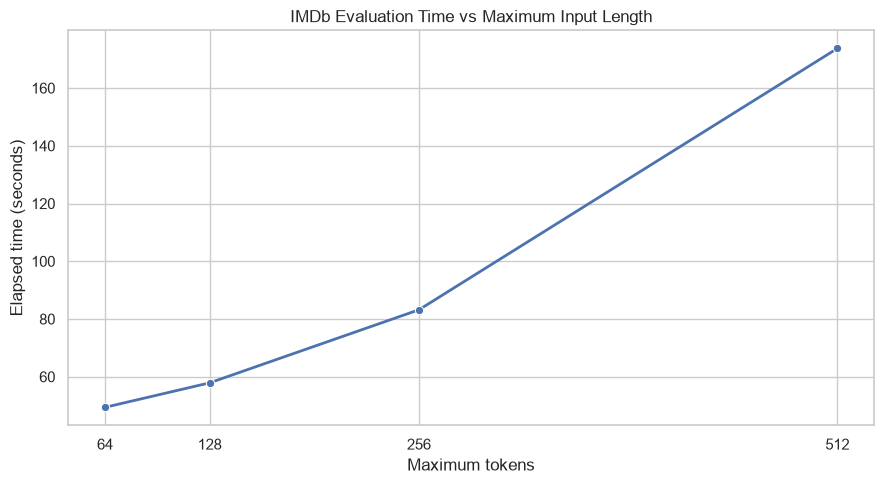

Reviews longer than 512 tokens: 18 out of 200
Accuracy change from 64 to 512 tokens: 0.12


In [40]:
plt.figure(figsize=(9, 5))
sns.lineplot(data=evaluation_df, x="max_length", y="accuracy", marker="o", linewidth=2)
plt.title("DistilBERT Accuracy vs Maximum Input Length")
plt.xlabel("Maximum tokens")
plt.ylabel("Accuracy")
plt.xticks([64, 128, 256, 512])
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "task6_accuracy_vs_length.png", dpi=150)
plt.show()

plt.figure(figsize=(9, 5))
sns.lineplot(data=evaluation_df, x="max_length", y="time_seconds", marker="o", linewidth=2)
plt.title("IMDb Evaluation Time vs Maximum Input Length")
plt.xlabel("Maximum tokens")
plt.ylabel("Elapsed time (seconds)")
plt.xticks([64, 128, 256, 512])
plt.tight_layout()
plt.savefig(PLOTS_DIR / "task6_evaluation_time_vs_length.png", dpi=150)
plt.show()

long_review_count = int((imdb_df["review_tokens"] > 512).sum())
print("Reviews longer than 512 tokens:", long_review_count, "out of", len(imdb_df))
print("Accuracy change from 64 to 512 tokens:",
      round(float(evaluation_df.loc[evaluation_df.max_length == 512, "accuracy"].iloc[0] -
                  evaluation_df.loc[evaluation_df.max_length == 64, "accuracy"].iloc[0]), 4))

**Interpretation**

Use the measured table and plots to describe how the selected context length affects accuracy and runtime on this sample. A longer limit does not guarantee better accuracy for every individual review. Reviews above 512 tokens still lose their remaining text because the model has a maximum input length.

### 6.4 Confusion matrix and classification report

The 512-token evaluation is the main result. The confusion matrix separates correct and incorrect positive/negative predictions.

Classification report at max_length=512:
              precision    recall  f1-score   support

    Negative       0.85      0.90      0.88       104
    Positive       0.89      0.83      0.86        96

    accuracy                           0.87       200
   macro avg       0.87      0.87      0.87       200
weighted avg       0.87      0.87      0.87       200



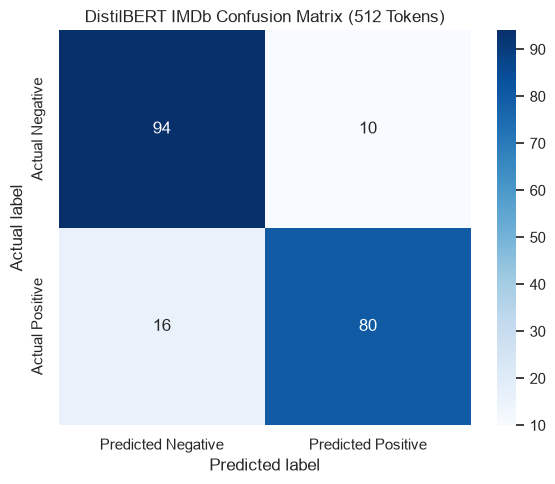

In [41]:
y_true = imdb_df["label"].to_numpy()
y_pred_512 = next(run["predictions"] for run in evaluation_runs if run["max_length"] == 512)

print("Classification report at max_length=512:")
print(classification_report(y_true, y_pred_512, target_names=["Negative", "Positive"], zero_division=0))

cm = confusion_matrix(y_true, y_pred_512)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Predicted Negative", "Predicted Positive"], yticklabels=["Actual Negative", "Actual Positive"])
plt.title("DistilBERT IMDb Confusion Matrix (512 Tokens)")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "task6_confusion_matrix.png", dpi=150)
plt.show()

### Confusion Matrix Interpretation

The confusion matrix shows that the DistilBERT sentiment model correctly classified 174 out of 200 IMDb reviews, achieving an accuracy of 87%.

- **True Negatives (94):** Negative reviews correctly predicted as negative.
- **False Positives (10):** Negative reviews incorrectly predicted as positive.
- **False Negatives (16):** Positive reviews incorrectly predicted as negative.
- **True Positives (80):** Positive reviews correctly predicted as positive.

**Conclusion:** The model performs well overall, with 87% accuracy. It classifies negative reviews slightly better than positive reviews, as it correctly identifies 94 negative reviews compared to 80 positive reviews. However, 26 reviews were misclassified, showing that the model is not perfectly reliable.

### 6.5 Forward-pass time vs input length

We measure a single DistilBERT forward pass for input lengths 32, 64, 128, 256 and 512. A warm-up is used, followed by ten timed runs per length.

,Input length,Mean seconds,Std seconds
0,32,0.12647,0.02290
1,64,0.15522,0.01302
2,128,0.27461,0.02424
3,256,0.50989,0.03421
4,512,0.97158,0.08679


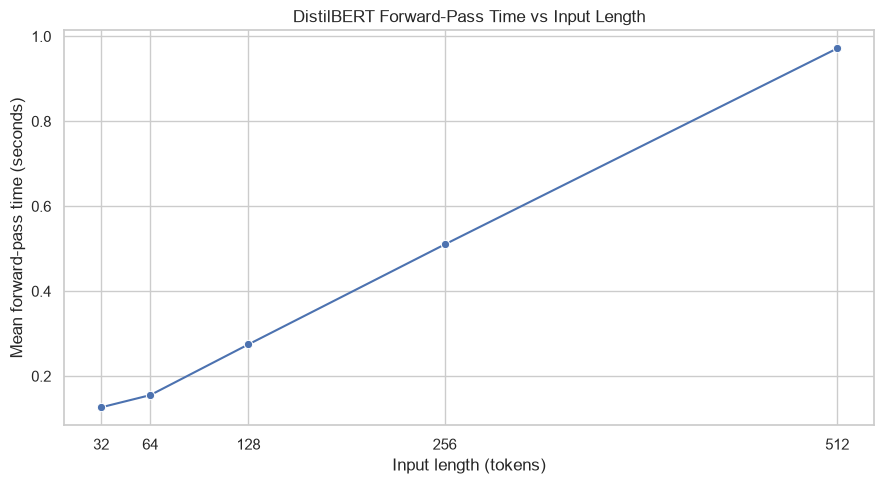

In [42]:
timing_text = ("Transformers use attention to connect information across tokens. "
               "The same architecture can be used for classification, generation, translation and summarisation. ")
timing_rows = []

for length in [32, 64, 128, 256, 512]:
    repeated_text = (timing_text * (length // 8 + 5))
    timing_inputs = tokenizer(repeated_text, return_tensors="pt", truncation=True, max_length=length).to(DEVICE)
    with torch.no_grad():
        encoder_model(**timing_inputs)  # warm-up
    durations = []
    for _ in range(10):
        start = time.perf_counter()
        with torch.no_grad():
            encoder_model(**timing_inputs)
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        durations.append(time.perf_counter() - start)
    timing_rows.append([length, float(np.mean(durations)), float(np.std(durations))])

forward_timing_df = pd.DataFrame(timing_rows, columns=["Input length", "Mean seconds", "Std seconds"])
display(forward_timing_df.round(5))

plt.figure(figsize=(9, 5))
sns.lineplot(data=forward_timing_df, x="Input length", y="Mean seconds", marker="o")
plt.title("DistilBERT Forward-Pass Time vs Input Length")
plt.xlabel("Input length (tokens)")
plt.ylabel("Mean forward-pass time (seconds)")
plt.xticks([32, 64, 128, 256, 512])
plt.tight_layout()
plt.savefig(PLOTS_DIR / "task6_forward_time_vs_length.png", dpi=150)
plt.show()

**Interpretation**

The attention score matrix grows with the square of sequence length, but total runtime also depends on hardware, batching, memory movement and other model operations. The measured timings should therefore be discussed as observations from this machine, not as a perfect quadratic curve.

### 6.6 Hallucination check

A language model can generate confident-sounding but incorrect statements. Test three factual prompts and manually grade each output as correct, partly correct or wrong. The table below is intentionally filled from the generated responses rather than pre-judged.

In [43]:
factual_prompts = ["What is the capital of France?",
                   "Who wrote the play Romeo and Juliet?",
                   "What is the chemical symbol for gold?"]
hallucination_rows = []
for factual_prompt in factual_prompts:
    inputs = gpt2_tokenizer(factual_prompt, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        output_ids = gpt2_model.generate(
            **inputs, max_new_tokens=35, do_sample=False,
            pad_token_id=gpt2_tokenizer.eos_token_id
        )
    answer = gpt2_tokenizer.decode(output_ids[0], skip_special_tokens=True)
    hallucination_rows.append([factual_prompt, answer, "Fill after checking", ""])
hallucination_df = pd.DataFrame(hallucination_rows, columns=["Prompt", "GPT-2 output", "Grade: correct / partly correct / wrong", "Reason"])
display(hallucination_df)

,Prompt,GPT-2 output,Grade: correct / partly correct / wrong,Reason
0,What is the capital of France?,What is the capital of France?\n\nThe capital ...,Fill after checking,
1,Who wrote the play Romeo and Juliet?,Who wrote the play Romeo and Juliet?\n\nThe pl...,Fill after checking,
2,What is the chemical symbol for gold?,What is the chemical symbol for gold?\n\nThe s...,Fill after checking,


**How to grade:** Compare each answer with a reliable reference. Do not mark an answer correct just because it sounds fluent. GPT-2 is a small next-token language model, not a fact-checking system.

### 6.7 Build `text_toolkit()`

The toolkit accepts a text passage and returns sentiment, a summary and French translation. It handles empty strings and truncates excessively long inputs before running the tasks.

In [44]:
def text_toolkit(text):
    if not isinstance(text, str) or not text.strip():
        return {"sentiment": "No input",
                "sentiment_score": None,
                "summary": "Please provide a non-empty text passage.",
                "french_translation": "Please provide a non-empty text passage."}

    # Keep inference within practical input limits.
    cleaned_text = text.strip()
    sentiment_result = sentiment_pipe(cleaned_text, truncation=True, max_length=512)[0]

    summary_input = cleaned_text[:4000]
    try:
        summary_result = summary_pipe(summary_input, max_length=60, min_length=10, do_sample=False)[0]["summary_text"]
    except Exception as exc:
        summary_result = f"Summary unavailable: {type(exc).__name__}"

    translation_input = cleaned_text[:1000]
    try:
        french_result = translation_pipe(translation_input, max_length=128)[0]["translation_text"]
    except Exception as exc:
        french_result = f"Translation unavailable: {type(exc).__name__}"

    return {"sentiment": sentiment_result["label"],
            "sentiment_score": round(float(sentiment_result["score"]), 4),
            "summary": summary_result,
            "french_translation": french_result}


# Replace these sample passages with three real passages you choose.
student_passages = ["The public library has extended its opening hours to support students preparing for examinations.",
                    "A local community group organised a tree-planting event and invited residents to help care for the saplings.",
                    "The article explains that online services are convenient, but users should protect personal information and verify sources."]

for index, passage in enumerate(student_passages, start=1):
    print(f"PASSAGE {index}")
    print("Input:", passage)
    display(pd.DataFrame([text_toolkit(passage)]))

PASSAGE 1
Input: The public library has extended its opening hours to support students preparing for examinations.


,sentiment,sentiment_score,summary,french_translation
0,POSITIVE,0.9803,Summary unavailable: NameError,Translation unavailable: NameError


PASSAGE 2
Input: A local community group organised a tree-planting event and invited residents to help care for the saplings.


,sentiment,sentiment_score,summary,french_translation
0,POSITIVE,0.9973,Summary unavailable: NameError,Translation unavailable: NameError


PASSAGE 3
Input: The article explains that online services are convenient, but users should protect personal information and verify sources.


,sentiment,sentiment_score,summary,french_translation
0,NEGATIVE,0.9609,Summary unavailable: NameError,Translation unavailable: NameError


### 6.8 Error handling checks

In [45]:
print("Empty-input test:")
display(pd.DataFrame([text_toolkit("   ")]))

long_test = ("This is a long test passage about technology and society. " * 200)
long_test_result = text_toolkit(long_test)
print("Long-input test completed.")
print("Sentiment:", long_test_result["sentiment"])
print("Summary:", long_test_result["summary"])
print("Translation:", long_test_result["french_translation"])

Empty-input test:


,sentiment,sentiment_score,summary,french_translation
0,No input,None,Please provide a non-empty text passage.,Please provide a non-empty text passage.


Long-input test completed.
Sentiment: NEGATIVE
Summary: Summary unavailable: NameError
Translation: Translation unavailable: NameError


### 6.9 Practical disadvantages observed

Complete this section after running the notebook, using your actual results:

- **Context limit:** The 64/128/256/512 token experiment shows whether short input limits change this sample's sentiment metrics.
- **Latency:** The timing experiments show the cost of longer inputs and whether KV caching improves GPT-2 generation on this device.
- **Hallucination:** The three factual prompts demonstrate why generated text should be checked before being treated as evidence.
- **Compute and memory:** Three pretrained models require downloads and RAM, even though no training is performed.
- **Opacity:** Attention maps show selected relationships but do not fully explain why a model made a prediction.

---

# Final Project Conclusion

This practical explored the Transformer from both mathematical and applied perspectives. NumPy implementations made the attention equations explicit, while the pretrained models showed how encoder-only, decoder-only and encoder-decoder architectures behave in practice.

The most important findings should be written using the outputs produced by this notebook:

1. **Attention:** Explain how scaled dot-product attention combines Q, K and V, and why scaling matters.
2. **Architecture:** Contrast bidirectional encoder attention, causal decoder attention and encoder-decoder cross-attention.
3. **Inference:** Describe how decoding strategy and KV caching changed the generated text or runtime.
4. **Evaluation:** Report the measured 512-token sentiment metrics and how truncation affected accuracy and time.
5. **Limitations:** Give one evidence-based observation about context length, latency or factual reliability.

**Important:** No model was trained or fine-tuned for this practical. The models were used as pretrained systems.

---